# This notebook illustrates the SED Fitting using non-parametric and parametric SFH models.
### 2 parametric models used: delayed exponential (or delayed tau) and double power-law. 
### 1 non-parametric model using continuity priors. 
### More details about these 3 models can be found in Carnall et al., 2019 (for parametric models) and Leja et al., 2019 (for non-parametric models). 

In [1]:
# Numpy 
import numpy as np

# Pandas  
import pandas as pd 

# Matplotlib packages
import matplotlib.pyplot as plt
from matplotlib import rc
from mpl_toolkits.axes_grid1 import make_axes_locatable, axes_size
from matplotlib.patches import Ellipse
%matplotlib inline
rc('axes', linewidth=2)

# Bagpipes 
import bagpipes as pipes

# Astropy packages
from astropy.wcs import WCS
from astropy.io import fits
from astropy.stats import sigma_clipped_stats, sigma_clip
import astropy.visualization as vis
from astropy.cosmology import Planck18 as cosmo
from astropy.visualization.wcsaxes import WCSAxes

# Photutils packages
from photutils.centroids import centroid_2dg, centroid_com, centroid_sources
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry
from photutils.background import Background2D, MedianBackground

# Remove warnings from the notebook
import warnings
warnings.filterwarnings('ignore')

# Imgutils 
from imgutils import *

# Now let's use the entire available screen width for the notebook
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))

# Define the Flat Lambda CDM model to calculate parameters like redshifts, cosmic ages 
from astropy.cosmology import FlatLambdaCDM
cosmo = FlatLambdaCDM(H0=70.0, Om0=0.3)

# Define the folder of your images
dir_images =  '/Users/quocanh1306/Downloads/'

# Define the folder to save your plots
dir_output = '/Users/quocanh1306/Desktop/Research/highredshiftgalaxies/ceers_research/Plots/'

#Define the dir of the info csv file of all galaxies in the studied sample 
dir_csv = '/Users/quocanh1306/Downloads/all_candidates_cat.csv'

#Load the catalog csv file
cat_selected = pd.read_csv(dir_csv)

Starting dense_basis. Failed to load FSPS, only GP-SFH module will be available.


In [2]:
# Id of the Galaxy investigated
idx = 20
Name = cat_selected["ID"].iloc[idx]

Filters = ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']

#information about the redshift of the astronomical source 
redshift = cat_selected["spec-z"].iloc[idx]

# Coordinates 
coord_ra = cat_selected["RA"].iloc[idx]
coord_dec = cat_selected["DEC"].iloc[idx]
age = cat_selected["age(Gyr)"].iloc[idx]

print('ID of galaxy: ', Name) 
print('List of filters: ', Filters)
print('Redshift: ', redshift)
print('Cosmic Age (Gyr): ', age)
print('RA: ', coord_ra)
print('DEC: ', coord_dec)

ID of galaxy:  62961
List of filters:  ['f090w', 'f115w', 'f150w', 'f200w', 'f277w', 'f356w', 'f410m', 'f444w']
Redshift:  3.6507936
Cosmic Age (Gyr):  1.6886561918563756
RA:  214.85057146215405
DEC:  52.86602964147236


In [3]:
# Check the photometry csv 
dir_phot = dir_images + f"phot_results_{idx}.csv"
phot_data = pd.read_csv(dir_phot)
print(phot_data)

   Unnamed: 0         0
0       f090w  0.002997
1       f115w  0.054971
2       f150w  0.229848
3       f200w  0.758673
4       f277w  1.768951
5       f356w  2.277274
6       f410m  2.806949
7       f444w  3.166809
8   f090w_err  0.006770
9   f115w_err  0.005124
10  f150w_err  0.005227
11  f200w_err  0.004610
12  f277w_err  0.003398
13  f356w_err  0.003213
14  f410m_err  0.008145
15  f444w_err  0.005013


In [4]:
# Define a loading function --> the SED fitting requires a loading function
def load_data(ID):
    dir_images =  '/Users/quocanh1306/Downloads/'
    dir_phot = dir_images + f"phot_results_{ID}.csv"
    phot_data = pd.read_csv(dir_phot)
    phot_array = [] 
    err_array = []
    for i in range(len(Filters) - 0):
        i = i + 0
        phot_array.append(phot_data.iloc[i][1])
        err_array.append(phot_data.iloc[i+len(Filters)][1])
    
    photometry = np.c_[phot_array, err_array]

    return photometry 

photometry = load_data(20)

print(photometry)

[[2.9974000e-03 6.7701000e-03]
 [5.4970700e-02 5.1243000e-03]
 [2.2984750e-01 5.2269000e-03]
 [7.5867330e-01 4.6101000e-03]
 [1.7689508e+00 3.3983000e-03]
 [2.2772738e+00 3.2127000e-03]
 [2.8069487e+00 8.1450000e-03]
 [3.1668093e+00 5.0134000e-03]]


In [5]:
# Define a fitting dictionary 
age_univ = cosmo.age(redshift).value
print ('redshift: %lf --> Age of the universe: %lf (Gyr)' % (redshift,age_univ))

# Define the delayed tau model 
fit_delayed = {}                                  
fit_delayed["age"] = (0.001, age_univ)        # Age in units of Gyr         
fit_delayed["age_prior"] = "log_10"
fit_delayed["tau"] = (0.001, 30.0)            # in units of Gyr
fit_delayed["tau_prior"] = "log_10"            
fit_delayed["massformed"] = (4., 12.)               # vary log_10(M*/M_solar)
fit_delayed["metallicity"] = (0.01, 2.5)            # in units of solar metallicity
fit_delayed["metallicity_prior"] = "log_10"

# Define the double power-law model 
fit_dblplaw = {}                        
fit_dblplaw["tau"] = (0., 15.)                # Vary the time of peak star-formation between
                                          # the Big Bang at 0 Gyr and 15 Gyr later. In 
                                          # practice the code automatically stops this
                                          # exceeding the age of the universe at the 
                                          # observed redshift.
            
fit_dblplaw["alpha"] = (0.01, 1000.)          # Vary the falling power law slope from 0.01 to 1000.
fit_dblplaw["beta"] = (0.01, 1000.)           # Vary the rising power law slope from 0.01 to 1000.
fit_dblplaw["alpha_prior"] = "log_10"         # Impose a prior which is uniform in log_10 of the 
fit_dblplaw["beta_prior"] = "log_10"          # parameter between the limits which have been set above as in Carnall et al. (2017).
fit_dblplaw["massformed"] = (4., 12.)
fit_dblplaw["metallicity"] = (0.01, 2.5)

# Define the non-parametric using continuity model 
continuity = {}
continuity["massformed"] = (4., 12.)
continuity["metallicity"] = (0.01, 2.5)
continuity["metallicity_prior"] = "log_10"
continuity["bin_edges"] = [0., 100., 250., 500., 1000., age_univ*1000]

for i in range(1, len(continuity["bin_edges"])-1):
    continuity["dsfr" + str(i)] = (-10., 10.)
    continuity["dsfr" + str(i) + "_prior"] = "student_t"
    #continuity["dsfr" + str(i) + "_prior_scale"] = 0.3  # Defaults to this value as in Leja19, but can be set
    #continuity["dsfr" + str(i) + "_prior_df"] = 2       # Defaults to this value as in Leja19, but can be set

# Define the dust model 
fit_dust = {}                                 # Dust component
fit_dust["type"] = "Calzetti"                 # Define the shape of the attenuation curve
fit_dust["Av"] = (0., 3.0)                    # Vary attenuation magnitudes in V band: Av between 0 and 2 magnitudes
fit_dust["eta"] = 1.0

# Define the nebular emission model 
fit_nebular = {}                              # Nebular emission component 
fit_nebular["logU"] = (-3.0, -1.0)            # Vary the log of ionization parameter U between -3 and -1

# Define the fit dictionary 
fit_instructions = {}                     # The fit instructions dictionary
fit_instructions["redshift"] = redshift
fit_instructions["dust"] = fit_dust
fit_instructions["nebular"] = fit_nebular
#fit_instructions["delayed"] = fit_delayed # Turn on when fitting delayed tau model 
#fit_instructions["dblplaw"] = fit_dblplaw # Turn on when fitting double power-law model 
fit_instructions["continuity"] = continuity # Currently selecting non-parametric model using continuity priors 


redshift: 3.650794 --> Age of the universe: 1.688656 (Gyr)


In [6]:
# Fitting with Bagpipes 
filter_list_jwst = ['filters/jwst_nircam_f090w.txt', 'filters/jwst_nircam_f115w.txt', 'filters/jwst_nircam_f150w.txt', 'filters/jwst_nircam_f200w.txt', 
       'filters/jwst_nircam_f277w.txt', 'filters/jwst_nircam_f356w.txt', 'filters/jwst_nircam_f410m.txt', 'filters/jwst_nircam_f444w.txt']

my_galaxy = pipes.galaxy(str(idx), load_data, phot_units='mujy', spectrum_exists=False, photometry_exists=True, filt_list=filter_list_jwst)
fit = pipes.fit(my_galaxy, fit_instructions, run="cont_qanh_Mar18")
fit.fit(verbose=False, n_live = 1000)


Results loaded from pipes/posterior/cont_qanh_Mar18/20.h5

Fitting not performed as results have already been loaded from pipes/posterior/cont_qanh_Mar18/20.h5. To start over delete this file or change run.



In [7]:
# Extract posterior for all advanced quantities 
fit.posterior.get_advanced_quantities()
list = list(fit.posterior.samples)
for i in range(len(list)): 
    print(list[i])

continuity:dsfr1
continuity:dsfr2
continuity:dsfr3
continuity:dsfr4
continuity:massformed
continuity:metallicity
dust:Av
nebular:logU
stellar_mass
formed_mass
sfr
ssfr
nsfr
mass_weighted_age
tform
tquench
mass_weighted_zmet
sfh
photometry
spectrum_full
uvj
chisq_phot
dust_curve


In [8]:
# Create a dataframe for posterior data 
posterior_data = {
    #'delayed:age': np.percentile(fit.posterior.samples["delayed:age"], (16, 50, 84)),
    #'delayed:massformed': np.percentile(fit.posterior.samples["delayed:massformed"], (16, 50, 84)),
    #'delayed:metallicity': np.percentile(fit.posterior.samples["delayed:metallicity"], (16, 50, 84)),            
    #'delayed:tau': np.percentile(fit.posterior.samples["delayed:tau"], (16, 50, 84)),
    #'continuity:dsfr1': np.percentile(fit.posterior.samples["continuity:dsfr1"],(16, 50, 84)),
    #'continuity:dsfr2': np.percentile(fit.posterior.samples["continuity:dsfr2"],(16, 50, 84)),
    #'continuity:dsfr3': np.percentile(fit.posterior.samples["continuity:dsfr3"],(16, 50, 84)),
    #'continuity:dsfr4': np.percentile(fit.posterior.samples["continuity:dsfr4"],(16, 50, 84)),
    list[0]: np.percentile(fit.posterior.samples[list[0]], (16, 50, 84)), 
    list[1]: np.percentile(fit.posterior.samples[list[1]], (16, 50, 84)),
    list[2]: np.percentile(fit.posterior.samples[list[2]], (16, 50, 84)),
    list[3]: np.percentile(fit.posterior.samples[list[3]], (16, 50, 84)),
    list[4]: np.percentile(fit.posterior.samples[list[4]], (16, 50, 84)),
    #list[5]: np.percentile(fit.posterior.samples[list[5]], (16, 50, 84)),
    'dust:Av': np.percentile(fit.posterior.samples["dust:Av"], (16, 50, 84)),
    'nebular:logU': np.percentile(fit.posterior.samples["nebular:logU"], (16, 50, 84)),
    'formed_mass': np.percentile(fit.posterior.samples["formed_mass"], (16, 50, 84)),
    'sfr': np.percentile(fit.posterior.samples["sfr"], (16, 50, 84)),
    'ssfr': np.percentile(fit.posterior.samples["ssfr"], (16, 50, 84)),
    'nsfr': np.percentile(fit.posterior.samples["nsfr"], (16, 50, 84)),
    'mass_weighted_age': np.percentile(fit.posterior.samples["mass_weighted_age"], (16, 50, 84)),  
    'tform': np.percentile(fit.posterior.samples["tform"], (16, 50, 84)),  
    'tquench': np.percentile(fit.posterior.samples["tquench"], (16, 50, 84)),  
    'mass_weighted_zmet': np.percentile(fit.posterior.samples["mass_weighted_zmet"], (16, 50, 84)),  
    'sfh': np.percentile(fit.posterior.samples["sfh"], (16, 50, 84)),  
    'photometry': np.percentile(fit.posterior.samples["photometry"], (16, 50, 84)), 
    'spectrum_full': np.percentile(fit.posterior.samples["spectrum_full"], (16, 50, 84)),     
    'uvj': np.percentile(fit.posterior.samples["uvj"], (16, 50, 84)),     
    'chisq_phot': np.percentile(fit.posterior.samples["chisq_phot"], (16, 50, 84)),     
    'dust_curve': np.percentile(fit.posterior.samples["dust_curve"], (16, 50, 84)),                           
}

fit_parameters = pd.DataFrame(data=posterior_data, index=['16th', '50th', '84th'])
print(fit_parameters.head())

      continuity:dsfr1  continuity:dsfr2  continuity:dsfr3  continuity:dsfr4  \
16th          2.917085         -1.332602         -1.032136          1.149295   
50th          3.833002         -1.131834         -0.535867          1.383422   
84th          5.390431         -0.771192         -0.431283          1.577851   

      continuity:massformed   dust:Av  nebular:logU  formed_mass        sfr  \
16th              10.973686  2.074239     -2.636543    10.973686  18.374112   
50th              10.981428  2.089656     -2.514956    10.981428  20.517101   
84th              10.987350  2.106722     -2.379228    10.987350  24.531303   

          ssfr  ...  mass_weighted_age     tform  tquench  mass_weighted_zmet  \
16th -9.523942  ...           0.350213  1.324118     99.0            0.054958   
50th -9.473816  ...           0.359865  1.328792     99.0            0.060798   
84th -9.398090  ...           0.364539  1.338444     99.0            0.066042   

             sfh    photometry  spect

In [9]:
# Display the posterior of different parameters 

from IPython.display import display, Math

post = fit.posterior.samples

#fit1 = np.percentile(post["stellar_mass"], (16, 50, 84))
#q = np.diff(fit1)
#txt = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
#txt = txt.format(fit1[1], q[0], q[1], r'\log(M_{*}[M_{\odot}])')
#display(Math(txt))

fit1 = np.power(10.0, np.percentile(post["stellar_mass"], (16, 50, 84)))/1e+7
q = np.diff(fit1)
txt = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
txt = txt.format(fit1[1], q[0], q[1], r'M_{*}/10^{8} M_{\odot}')
display(Math(txt))

fit1 = np.log10(np.percentile(post["sfr"], (16, 50, 84)))
q = np.diff(fit1)
txt = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
txt = txt.format(fit1[1], q[0], q[1], r'\log(SFR[M_{\odot}yr^{-1}])')
display(Math(txt))

fit1 = np.percentile(post["sfr"], (16, 50, 84))
q = np.diff(fit1)
txt = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
txt = txt.format(fit1[1], q[0], q[1], r'SFR[M_{\odot}yr^{-1}]')
display(Math(txt))

fit1 = np.percentile(post["mass_weighted_age"], (16, 50, 84)) * 1e+3
q = np.diff(fit1)
txt = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
txt = txt.format(fit1[1], q[0], q[1], r'Age_{M} [Myr]')
display(Math(txt))

fit1 = np.log10(np.percentile(post["continuity:metallicity"], (16, 50, 84)))
q = np.diff(fit1)
txt = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
txt = txt.format(fit1[1], q[0], q[1], r'\log(Z/Z_{\odot})')
display(Math(txt))

fit1 = np.percentile(post["dust:Av"], (16, 50, 84))
q = np.diff(fit1)
txt = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
txt = txt.format(fit1[1], q[0], q[1], r'A_{V}[mag]')
display(Math(txt))

fit1 = np.percentile(np.log10(post["sfr"]) - post["stellar_mass"], (16, 50, 84))
q = np.diff(fit1)
txt = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
txt = txt.format(fit1[1], q[0], q[1], r'\log(sSFR[yr^{-1}])')
display(Math(txt))

fit1 = np.percentile(post["tquench"], (16, 50, 84))
q = np.diff(fit1)
txt = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
txt = txt.format(fit1[1], q[0], q[1], r't_{quench}[Myr]')
display(Math(txt))

fit1 = np.percentile(post["tform"], (16, 50, 84))
q = np.diff(fit1)
txt = "\mathrm{{{3}}} = {0:.2f}_{{-{1:.2f}}}^{{{2:.2f}}}"
txt = txt.format(fit1[1], q[0], q[1], r't_{form}[Myr]')
display(Math(txt))

## The minimum value of chi-square
imodel = np.argmin(fit.posterior.samples['chisq_phot'])
imodels = [imodel]
chisq = fit.posterior.samples['chisq_phot'][imodel]
nbands = len(filter_list_jwst)
print (chisq)

display(Math(r'\chi_{\nu}^{2} = %.2lf' % (chisq/nbands)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

242.58087399168204


<IPython.core.display.Math object>

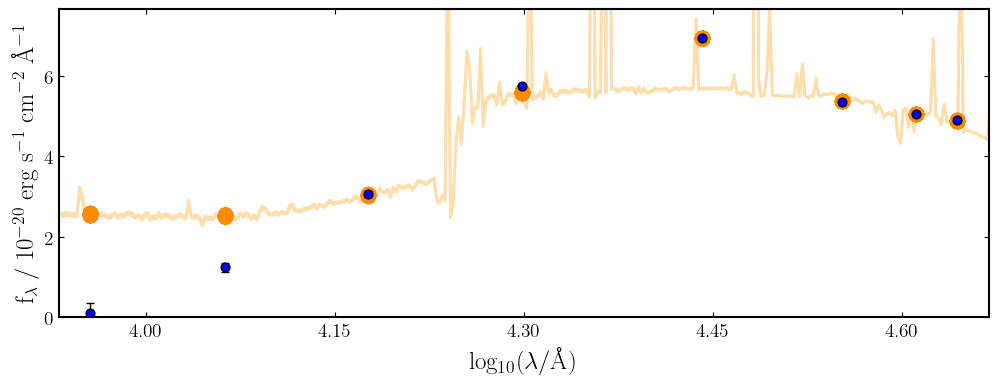

In [10]:
# Make spectrum posterior plot 
fig, ax = fit.plot_spectrum_posterior(save=False, show=True)
save_path = f'/Users/quocanh1306/Downloads/cont_spectrum_posterior_{idx}.png' # Define save path 
fig.savefig(save_path, bbox_inches='tight', dpi=300, facecolor='white')

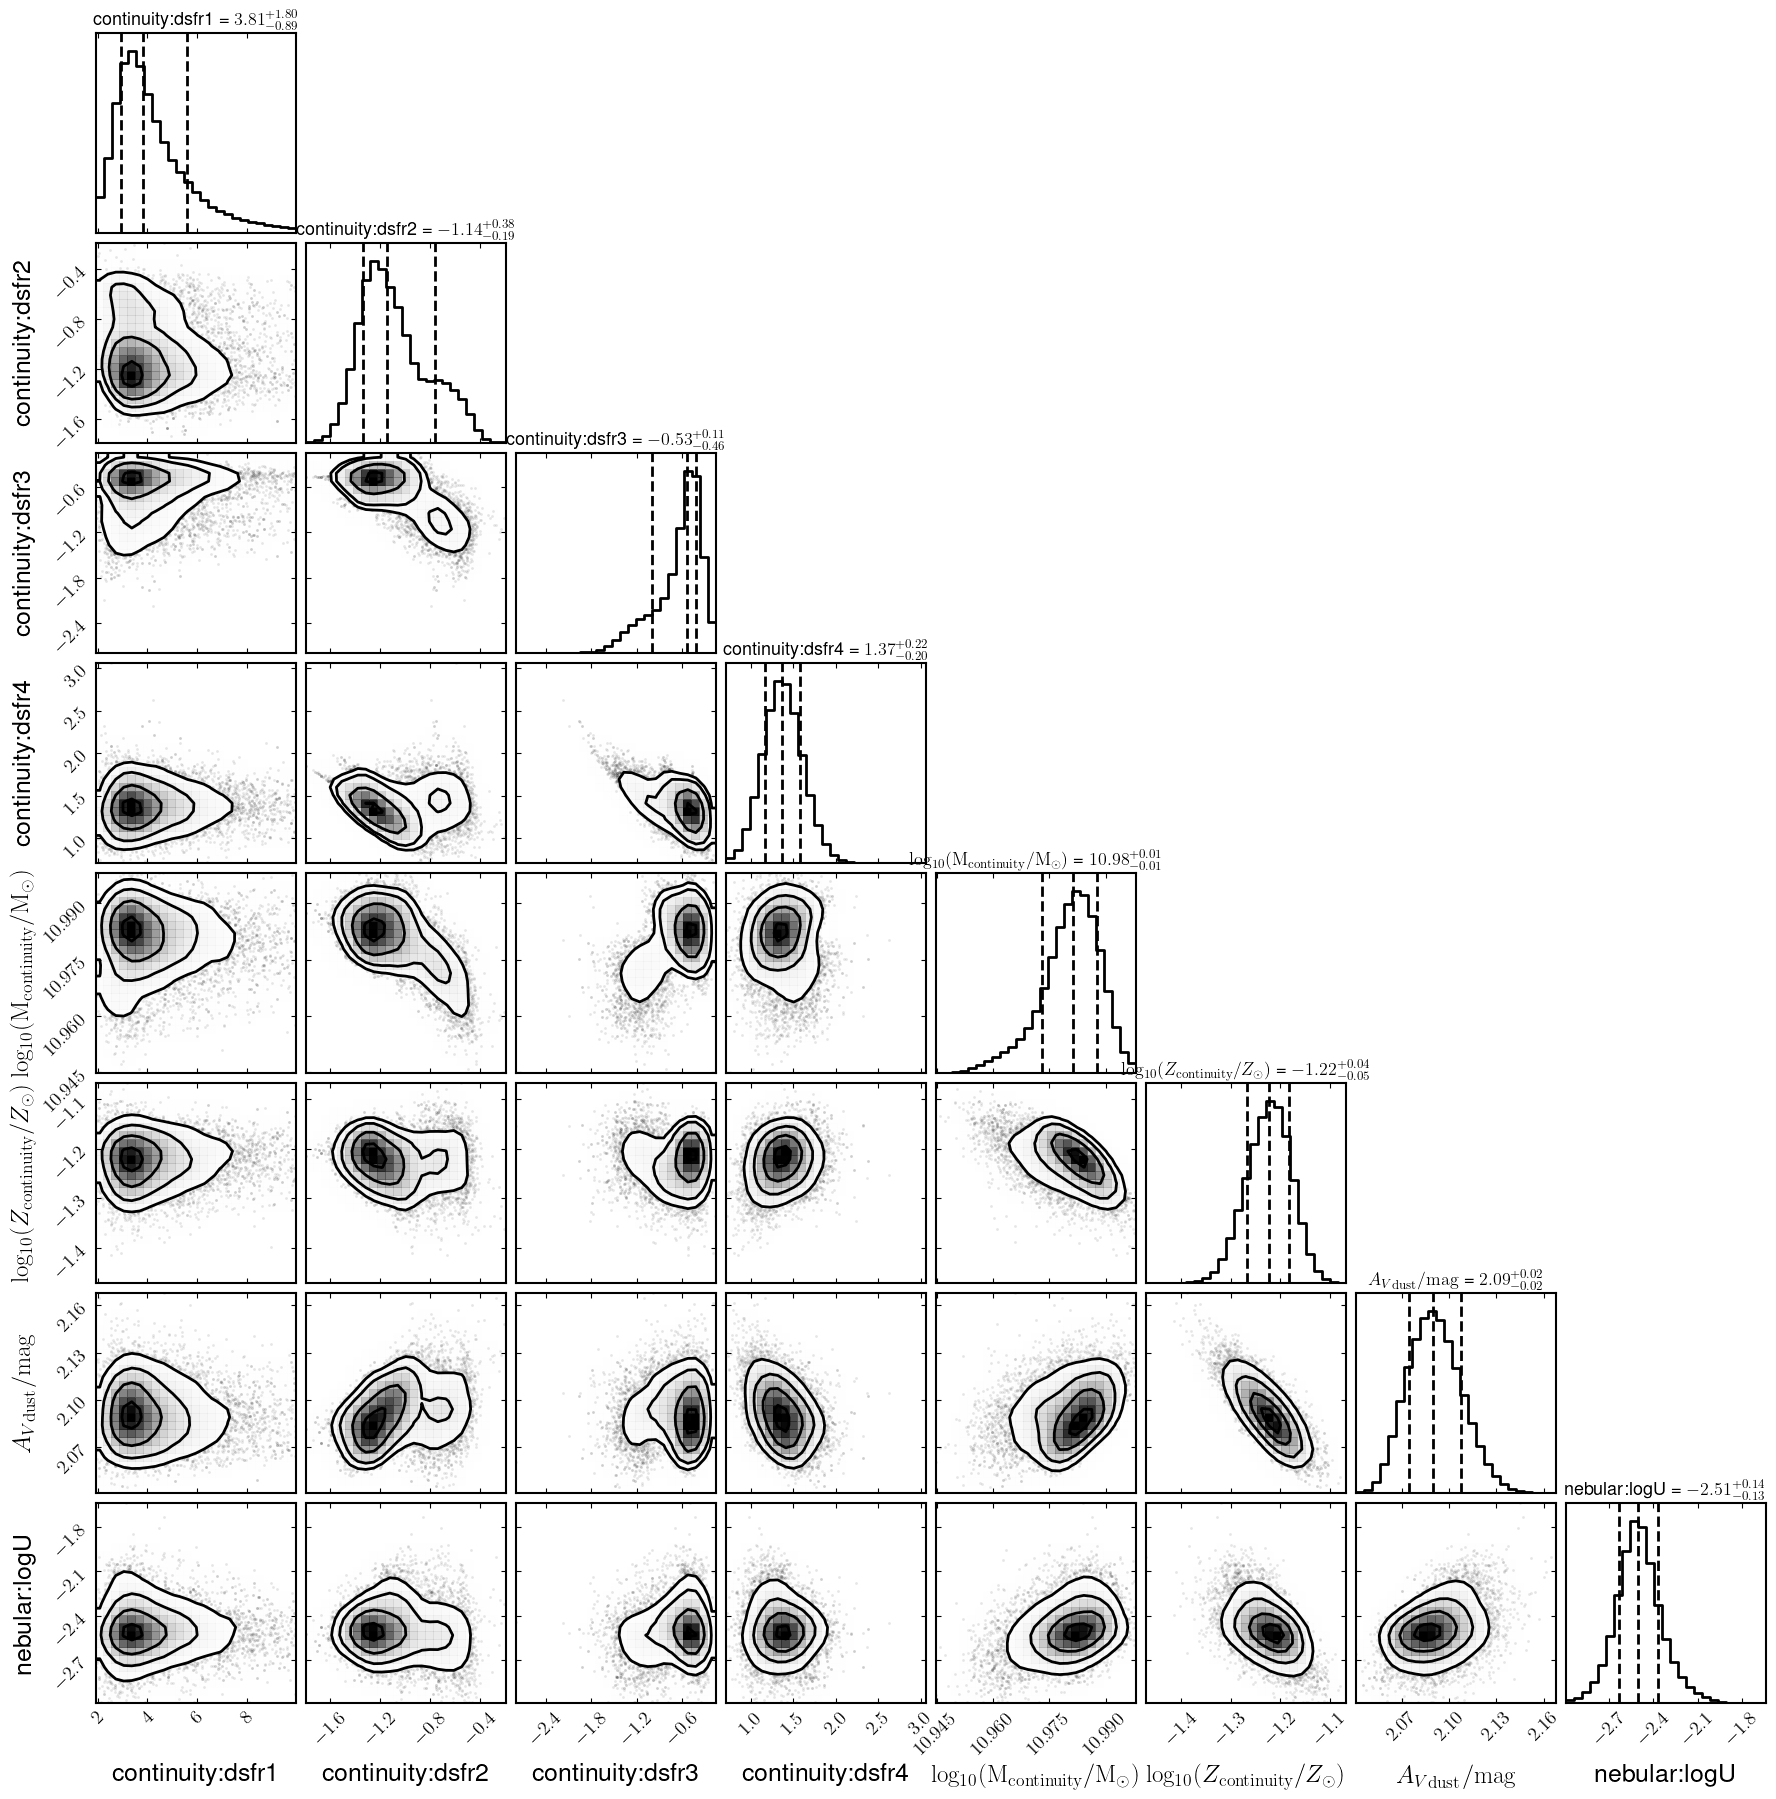

In [12]:
# Make corner plot 
fig1 = fit.plot_corner(save=False, show=True)
save_path1 = f'/Users/quocanh1306/Downloads/cont_corner_{idx}.png' # Define save path 
fig1.savefig(save_path1, bbox_inches='tight', dpi=300, facecolor='white')

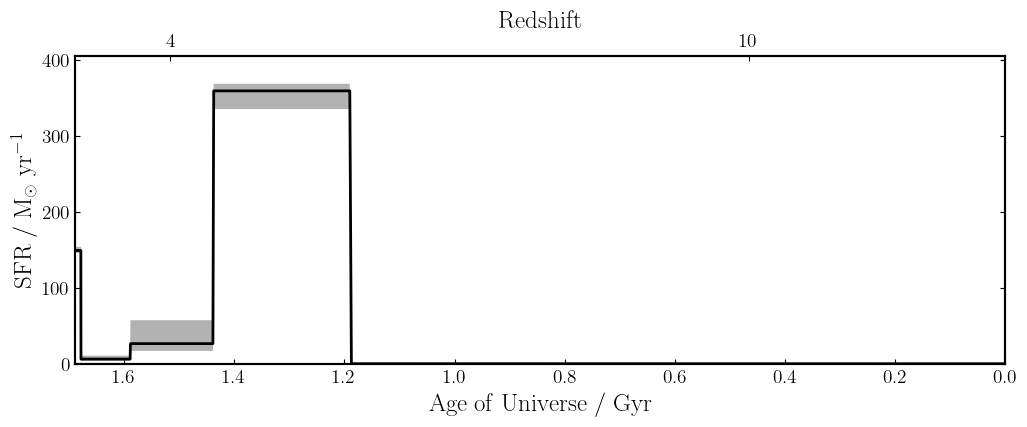

In [14]:
# Make SFH posterior plot 
fig2, ax = fit.plot_sfh_posterior(save=False, show=True)
save_path2 = f'/Users/quocanh1306/Downloads/cont_SFH_{idx}.png'  # Define save path 
fig2.savefig(save_path2, bbox_inches='tight', dpi=300, facecolor='white')

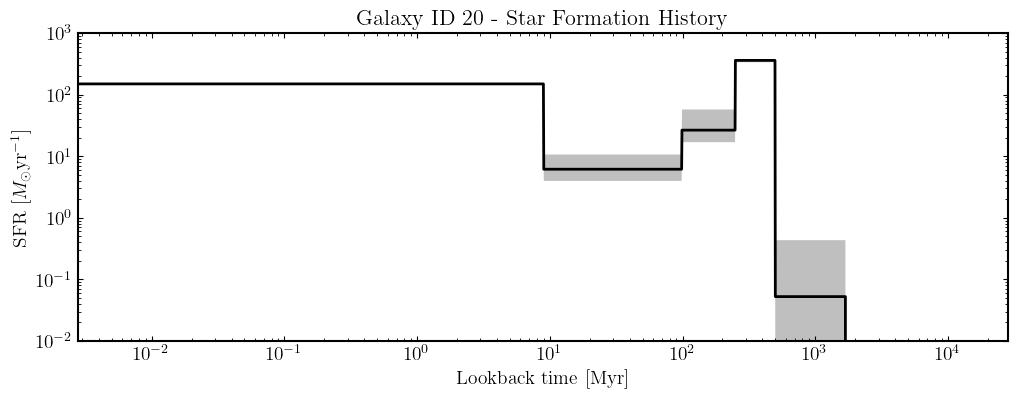

In [15]:
# Plot the SFH posterior again in logscale 

# Extract the x-axis 
max_age = max(fit.posterior.sfh.ages*10**-9)
post_sfh_t = max_age - fit.posterior.sfh.ages*10**-9
post_sfh_lbt = fit.posterior.sfh.ages*10**-9

# Extract the y-axis 
post_sfh_sfr = np.percentile(fit.posterior.samples["sfh"], (16, 50, 84), axis=0).T

fig = plt.figure(figsize=(12,4))
f1 = plt.subplot()
plt.ylim(0.01, 1000.0)
f1.set_yscale('log')
f1.set_xscale('log')
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
plt.xlabel('Lookback time [Myr]', fontsize=14)
plt.ylabel(r'SFR [$M_{\odot}\rm{yr}^{-1}$]', fontsize=14)
plt.plot(post_sfh_lbt*1e+3-1.0, post_sfh_sfr[:, 1], color='black', zorder=1)
plt.fill_between(post_sfh_lbt*1e+3-1.0, post_sfh_sfr[:, 0], post_sfh_sfr[:, 2], color='gray', alpha=0.5, zorder=0, lw=0)
plt.title(f'Galaxy ID {idx} - Star Formation History', fontsize = 16)
save_path = f'/Users/quocanh1306/Downloads/cont_SFH_log_{idx}.png'  # Define save path 
fig.savefig(save_path, bbox_inches='tight', dpi=300, facecolor='white')

In [16]:
# Sum stellar mass formed within the last 10 Myr
mass_10myr = ((5.0*1e+6*122.743567) + (5.0*1e+6*21.678495)) * 2.2 / 10
print ('%e' % mass_10myr)

1.588643e+08


In [17]:
def analyze_star_formation(lookback_time, sfr, milestones=None):
    """
    Analyzes a star formation history to calculate cumulative stellar mass
    and the percentage of mass formed at specific lookback times.

    Args:
        lookback_time (list or np.ndarray): Array of lookback times in millions of years (Myr).
                                            The array should be sorted from most recent (0) to most distant.
        sfr (list or np.ndarray): Array of star formation rates (SFR) in solar masses per year (Msun/yr),
                                  corresponding to the lookback_time array.
        milestones (list, optional): A list of lookback times (in Myr) at which to calculate the
                                     percentage of mass formed. Defaults to [1000, 5000, 10000].

    Returns:
        tuple: A tuple containing:
            - np.ndarray: The original lookback_time array, sorted from past to present.
            - np.ndarray: The cumulative stellar mass in solar masses (Msun) as a function of time.
            - dict: A dictionary where keys are the milestone lookback times and values are the
                    percentage of the total mass formed by that time.
    """
    if milestones is None:
        milestones = [1000, 5000, 10000] # Default milestones: 1, 5, and 10 Gyr ago

    # Convert inputs to numpy arrays for easier computation
    lookback_time = np.asarray(lookback_time)
    sfr = np.asarray(sfr)

    # Sort the arrays based on lookback time, from the earliest time to the present
    sort_indices = np.argsort(lookback_time)[::-1]
    lookback_time_sorted = lookback_time[sort_indices]
    sfr_sorted = sfr[sort_indices]
    
    # Convert lookback time from Myr to years
    time_years = lookback_time_sorted * 1e6

    # Calculate the positive time difference between each step (in years)
    # We integrate forward in time (from largest lookback time to present).
    # The interval is the time between a step and the next one in the sorted array.
    dt_intervals = time_years[:-1] - time_years[1:]
    # The cumulative mass at the very first (earliest) time step is 0.
    # We use its SFR for the first time interval, so we append a 0 for the last interval.
    dt = np.append(dt_intervals, 0)


    # Calculate the mass formed in each time interval.
    # We use the SFR at the beginning of an interval, applied over that interval's duration.
    mass_formed = sfr_sorted * dt

    # Calculate the cumulative stellar mass over time
    cumulative_mass = np.cumsum(mass_formed)

    # Total mass is the last value in the cumulative mass array
    total_mass = cumulative_mass[-1]
    
    if total_mass == 0:
        print("Warning: Total mass formed is zero. Cannot calculate percentages.")
        return lookback_time_sorted, cumulative_mass, {m: 0 for m in milestones}

    # Calculate the percentage of mass formed at specified milestones
    mass_percentages = {}
    for milestone in milestones:
        # Find the cumulative mass at the milestone time using interpolation
        # We use np.interp to find the cumulative mass at the exact milestone lookback time
        # Note: interp needs x-coordinates to be increasing, so we reverse the arrays for it.
        mass_at_milestone = np.interp(milestone, lookback_time_sorted[::-1], cumulative_mass[::-1])
        percentage = (mass_at_milestone / total_mass) * 100
        mass_percentages[milestone] = percentage

    return lookback_time_sorted, cumulative_mass, mass_percentages, total_mass


In [18]:
idx1 = np.where(post_sfh_sfr[:, 1]>0.0)[0]
lookback_time_sorted, cumulative_mass, mass_percentages, total_mass = analyze_star_formation(post_sfh_lbt[idx1]*1e+3-1.0, post_sfh_sfr[idx1, 1], milestones=[2.0, 3.0, 5.0, 10.0, 100.0])

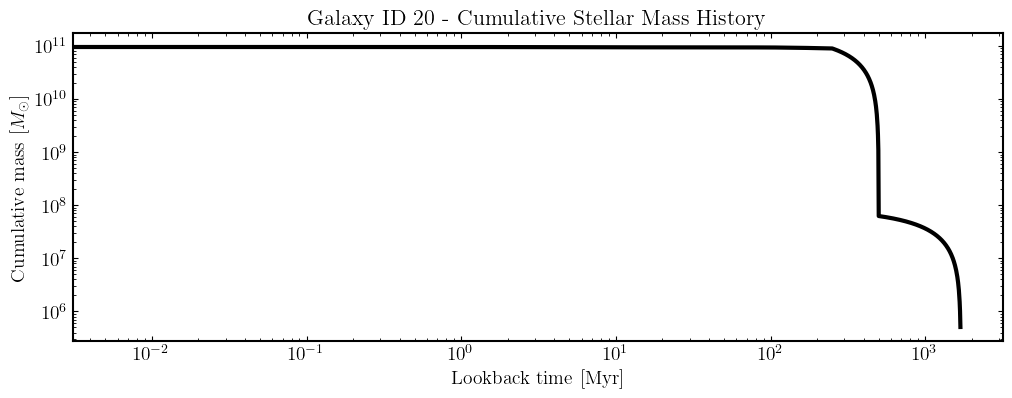

In [20]:
# Make the cumulative stellar mass history plot 
fig = plt.figure(figsize=(12,4))
f1 = plt.subplot()
f1.set_yscale('log')
f1.set_xscale('log')
#plt.xlim(0.1, 1000.0)
#plt.ylim(0.001, 1000.0)
plt.xlabel('Lookback time [Myr]', fontsize=14)
plt.ylabel(r'Cumulative mass [$M_{\odot}$]', fontsize=14)
plt.title(f'Galaxy ID {idx} - Cumulative Stellar Mass History', fontsize = 16)
plt.plot(lookback_time_sorted, cumulative_mass, lw=3, color='black')